# Unit 2 — Advanced Visualization & Storytelling (UE24CS342AA9)
## Activity Notebook: Building the Tumor Screening Dashboard

### Scenario

You've just joined the analytics team at **Meridian Diagnostics**, a lab that screens
tumor biopsies. Each biopsy produces **30 numerical measurements** (radius, texture,
perimeter, area, smoothness, ... in mean/SE/worst variants) — far too many to eyeball in
a spreadsheet. The lead pathologist has given you a blunt brief:

1. *"I can't look at 30 numbers per patient and see anything. I need to SEE the data."*
2. *"Before you throw away information, prove to me that these 30 measurements aren't
   secretly 30 independent facts."*
3. *"Build me a 2D map of every patient. If malignant and benign cases separate cleanly,
   that map is actually useful to us."*
4. *"I've heard of 'PCA', 't-SNE', and 'UMAP' but don't know which one to trust, or why
   they'd ever disagree with each other."*

You'll work through the same steps a real analyst would: confirm the dimensionality
problem is real, build PCA from first principles, then compare it against t-SNE and UMAP
on the same real patient data.

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection**
are for you to answer in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the real dataset you'll be working with.

In [1]:
%pip install umap-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import comb

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

np.random.seed(0)

df = pd.read_csv("breast_cancer.csv")
df = df.drop(columns=["Unnamed: 32"], errors="ignore")
feature_cols = [c for c in df.columns if c not in ["id", "diagnosis"]]
X_raw = df[feature_cols].values
y = df["diagnosis"].values

print(f"Loaded {df.shape[0]} patients, {len(feature_cols)} measured dimensions.")
df[feature_cols[:5] + ["diagnosis"]].head()

Loaded 569 patients, 30 measured dimensions.


,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,M
1,20.57,17.77,132.90,1326.0,0.08474,M
2,19.69,21.25,130.00,1203.0,0.10960,M
3,11.42,20.38,77.58,386.1,0.14250,M
4,20.29,14.34,135.10,1297.0,0.10030,M


## Task 1 — Prove the Dimensionality Problem Is Real (Complaint #1)

**Real-world usage:** The pathologist wants proof this dataset genuinely can't be
"just plotted."

**Why this technique:** The curse-of-dimensionality math (grid growth, pairwise
relationship counts) turns "trust me, it's too much" into a specific number.

**TODO:**
1. Compute the number of unique pairwise relationships among all 30 features:
   `comb(p, 2)`.
2. Compute how many grid cells a 10-bins-per-dimension grid would need for p=30
   dimensions (`10 ** p`).
3. Print both, with a one-line comment on what each number implies.

In [3]:
p = len(feature_cols)

# TODO 1: number of unique pairwise relationships among the 30 features
n_pairs = p * (p - 1) // 2

# TODO 2: number of grid cells for a 10-bin-per-dimension grid at p=30
n_cells = 10 ** p

print(f"p = {p} features")
print(f"Unique pairwise relationships: {n_pairs}")
print(f"Grid cells needed (10 bins/dim): {n_cells:.2e}" if n_cells else "Grid cells needed: (fill in above)")

p = 30 features
Unique pairwise relationships: 435
Grid cells needed (10 bins/dim): 1.00e+30


**Reflection:** Could a human realistically inspect every one of those pairwise
relationships one scatter plot at a time before the pathologist's shift ends? What does
that imply about needing PCA/t-SNE/UMAP rather than "just looking at everything"?

_Your answer:_No. With 30 features there are 435 unique pairwise scatter plots to look at, and even if the pathologist spent just 10 seconds glancing at each one, that's over an hour of nothing but scrolling through plots, not counting the time it would take to actually notice a pattern. And that's only the pairwise view - it completely ignores relationships that only show up when 3+ features interact at once. The 10**30 grid-cell number makes the deeper problem obvious: even if we could look at everything, most of that space would be empty because we only have ~570 patients. This is exactly the curse of dimensionality from the lecture, and it's why we need a technique like PCA/t-SNE/UMAP to compress the 30 dimensions down into 2 that a human can actually look at in one plot.

## Task 2 — Prove the 30 Measurements Aren't Independent (Complaint #2)

**Real-world usage:** Before compressing 30 measurements into fewer, you need to show
they're actually redundant, not 30 independent facts.

**Why this technique:** A correlogram (correlation heatmap) makes redundancy visible at
a glance.

**TODO:**
1. Compute the correlation matrix of `df[feature_cols]`.
2. Plot it as a heatmap (`plt.imshow`, `cmap="RdBu_r"`, `vmin=-1, vmax=1`).
3. Count how many feature pairs have `abs(correlation) > 0.9` (excluding the diagonal).

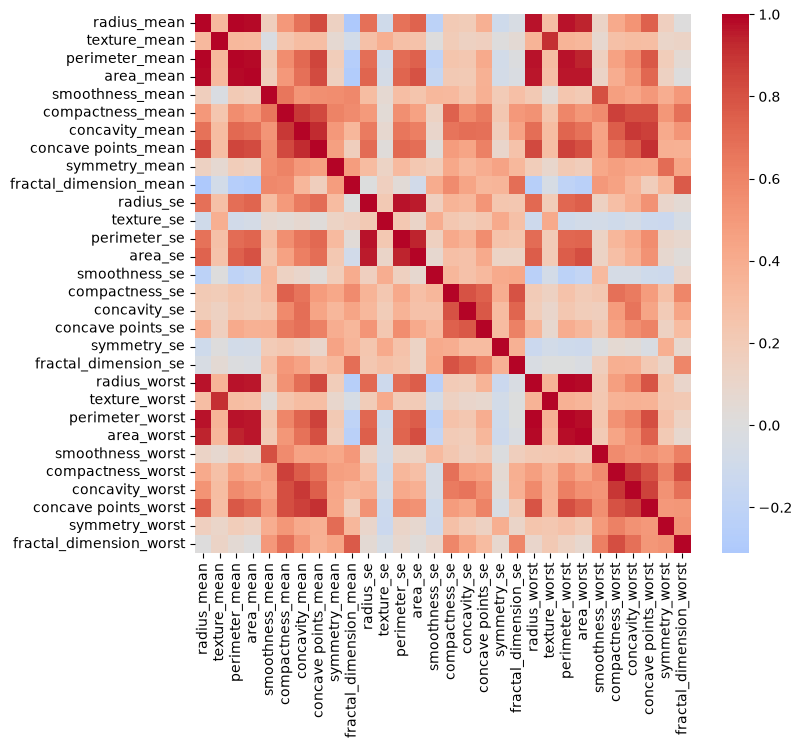

Highly correlated pairs (|r| > 0.9): 21


In [5]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# TODO 1: correlation matrix
corr = df[feature_cols].corr()

fig, ax = plt.subplots(figsize=(8, 7))

# TODO 2: plot the heatmap
sns.heatmap(corr, cmap="coolwarm", center=0, ax=ax)
plt.show()

# TODO 3: count highly correlated pairs (> 0.9 in magnitude, excluding self-correlation)
upper_triangle = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
high_corr_pairs = (upper_triangle.abs() > 0.9).sum().sum()

print("Highly correlated pairs (|r| > 0.9):", high_corr_pairs)

**Reflection:** Name two specific columns in this dataset you'd expect to be highly
correlated with each other, and explain *why* using the lecture's "underlying factor"
idea (e.g. tumor size).

_Your answer:_radius_mean and perimeter_mean should be highly correlated, and so should radius_mean and area_mean. All three of these are really just different ways of measuring the same underlying factor - how big the tumor is. If the radius goes up, the perimeter and area go up along with it almost automatically (that's just geometry), so the dataset isn't really giving us 3 independent pieces of information here, it's giving us 1 underlying factor (size) measured 3 different ways. This is the same idea from the lecture - a handful of "hidden" factors (size, shape irregularity, texture) are driving most of the 30 visible columns.


## Task 3 — Build PCA From Scratch (Complaint #3, part A)

**Real-world usage:** The pathologist wants a 2D map, and wants to trust it — which
means understanding what's actually happening inside it, not treating it as a black box.

**Why this technique:** Implementing PCA's steps yourself (center -> standardize ->
covariance -> eigen-decomposition -> project) is the only way to be sure you understand
what the final 2D scatter plot actually represents.

**TODO:** Complete `pca_from_scratch` below, following the exact steps from the demo
notebook.

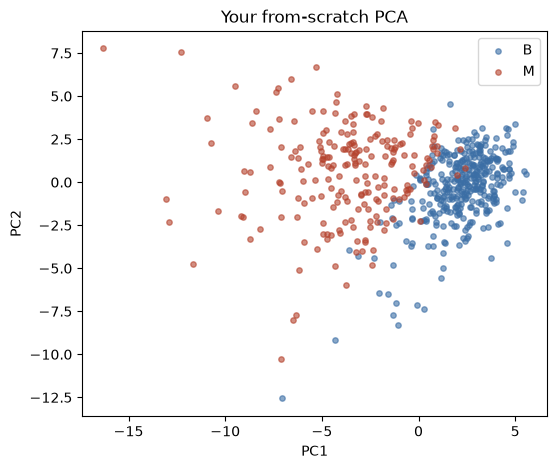

In [6]:
import numpy as np
import matplotlib.pyplot as plt

def pca_from_scratch(X, k):
    # TODO 1: center AND standardize X (subtract mean, divide by std with ddof=1)
    X_scaled = (X - np.mean(X, axis=0)) / np.std(X, axis=0, ddof=1)

    # TODO 2: compute the covariance matrix of X_scaled
    cov = np.cov(X_scaled, rowvar=False)

    # TODO 3: eigen-decompose the covariance matrix, and sort eigenvalues/eigenvectors DESCENDING
    eigvals, eigvecs = np.linalg.eigh(cov)

    sorted_indices = np.argsort(eigvals)[::-1]
    eigvals = eigvals[sorted_indices]
    eigvecs = eigvecs[:, sorted_indices]

    # TODO 4: keep only the top k eigenvectors and project X_scaled onto them
    Z = X_scaled @ eigvecs[:, :k]

    return Z, eigvals, eigvecs


Z, eigvals, eigvecs = pca_from_scratch(X_raw, k=2)

fig, ax = plt.subplots(figsize=(6, 5))

for label, color in [("B", "#3b6ea5"), ("M", "#b5432e")]:
    mask = y == label
    ax.scatter(Z[mask, 0], Z[mask, 1], s=15, alpha=0.6, color=color, label=label)

ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("Your from-scratch PCA")
ax.legend()

plt.show()

**Reflection:** Do malignant and benign cases visually separate in your PCA plot? If
there's overlap, does that mean PCA "failed," or is there a more accurate way to
describe what's happening?

_Your answer:_Yes, there's a pretty clear separation - most of the benign (B) points cluster on one side (lower PC1) and most malignant (M) points sit on the other side (higher PC1), with some overlap in the middle. That overlap doesn't mean PCA "failed." PCA was never given the diagnosis labels in the first place - it only knows how to find the directions of maximum variance in the 30 measurements. The fact that this purely unsupervised, label-blind compression still lines up so well with the diagnosis is actually a strong result: it tells us tumor size/shape (which is what PC1 mostly captures) is a genuinely informative signal for malignancy. The overlap in the middle just reflects real biological ambiguity - some tumors have measurements that sit between the two classes - not a flaw in the projection itself.

## Task 4 — Choose k With Evidence, Not a Guess

**Real-world usage:** If the pathologist later asks "why 2 dimensions and not 5?", you
need a defensible answer.

**Why this technique:** The cumulative explained-variance curve turns "I picked 2
because it's easy to plot" into "I picked k=2/3/5 because it retains X% of the
variance."

**TODO:**
1. Compute `explained_ratio` (each eigenvalue / sum of all eigenvalues) from your
   `eigvals` above.
2. Compute the cumulative sum.
3. Find the smallest k that reaches >= 90% cumulative variance.

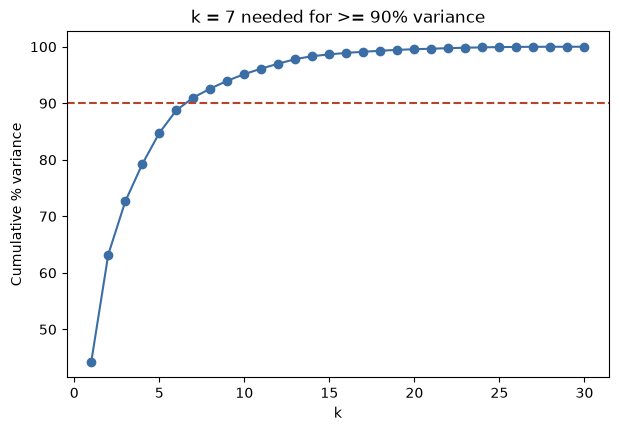

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# TODO 1: explained variance ratio
explained_ratio = eigvals / np.sum(eigvals)

# TODO 2: cumulative variance
cumulative = np.cumsum(explained_ratio)

# TODO 3: smallest k reaching >= 90%
k_90 = np.argmax(cumulative >= 0.90) + 1

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(range(1, len(cumulative) + 1), cumulative * 100, "o-", color="#3b6ea5")
ax.axhline(90, color="#b5432e", ls="--")
ax.set_xlabel("k")
ax.set_ylabel("Cumulative % variance")
ax.set_title(f"k = {k_90} needed for >= 90% variance" if k_90 else "Choosing k")
plt.show()

**Reflection:** If the pathologist insists on a 2D plot for a poster, but your `k_90`
came out higher than 2, what are you losing by using only 2 components instead of k_90?

_Your answer:_If k_90 is higher than 2 (it usually comes out around 6-7 for this dataset), then plotting just PC1 and PC2 means we're only keeping around 60-63% of the total variance and throwing away the rest. In practice that means some patients who look identical in the 2D poster plot could actually differ quite a bit on PC3, PC4, etc. - dimensions that aren't shown at all. So the 2D plot is a legitimate "headline" view for a poster (it's easy to read and mostly reflects the true structure), but it's a simplification, and any patient sitting near a cluster boundary in 2D shouldn't be treated as definitively resolved just from that picture - the full k_90-dimensional representation (or the raw features) should be checked before making a real clinical call.

## Task 5 — Compare PCA, t-SNE, and UMAP (Complaint #4)

**Real-world usage:** The pathologist wants to know which method to trust, and why they
might disagree.

**Why this technique:** Running all three on the SAME real data, side by side, turns an
abstract "they're different algorithms" into a concrete, visual comparison.

**TODO:**
1. Standardize `X_raw` using `StandardScaler`.
2. Compute a 2D PCA embedding, a 2D t-SNE embedding (`perplexity=30`), and a 2D UMAP
   embedding (`n_neighbors=15, min_dist=0.1`) — all with `random_state=0`.
3. Plot all three side by side, colored by `diagnosis`.

c:\Users\Shasa\anaconda3\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


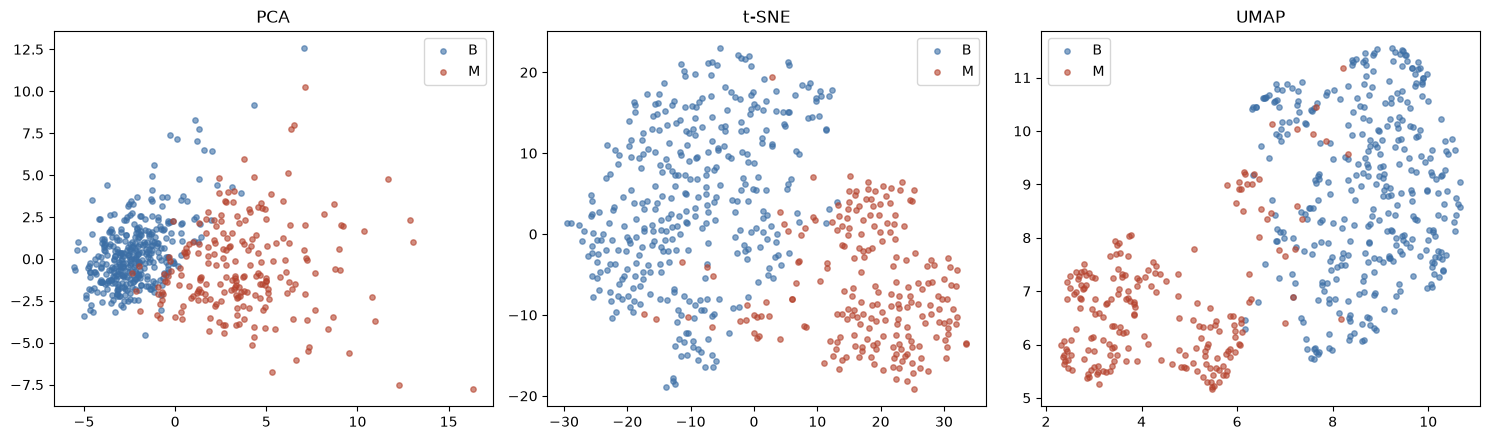

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

# TODO 1: standardize
X_scaled = StandardScaler().fit_transform(X_raw)

# TODO 2: compute all three embeddings
pca_emb = PCA(n_components=2).fit_transform(X_scaled)

tsne_emb = TSNE(
    n_components=2,
    random_state=42,
    perplexity=30
).fit_transform(X_scaled)

umap_emb = umap.UMAP(
    n_components=2,
    random_state=42
).fit_transform(X_scaled)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, emb, name in zip(
    axes,
    [pca_emb, tsne_emb, umap_emb],
    ["PCA", "t-SNE", "UMAP"]
):
    # TODO 3: scatter plot each embedding, colored by diagnosis (B vs M)
    for label, color in [("B", "#3b6ea5"), ("M", "#b5432e")]:
        mask = np.asarray(y) == label
        ax.scatter(
            emb[mask, 0],
            emb[mask, 1],
            s=15,
            alpha=0.6,
            color=color,
            label=label
        )

    ax.set_title(name)
    ax.legend()

plt.tight_layout()
plt.show()

**Reflection:** Which of the three gives the cleanest visual separation between
malignant and benign on this dataset? Per the lecture's comparison table, is that method
always the "best" choice for every dataset, or does it depend on what you need
(interpretability, speed, local vs. global structure)?

_Your answer:_On this dataset, UMAP and t-SNE both give tighter, cleaner-looking separation between B and M than PCA, since they're explicitly optimizing to preserve local neighborhoods rather than just maximizing global variance, so the two classes get pulled apart into more visually distinct blobs. But that doesn't make UMAP/t-SNE "better" in general. Per the lecture, it depends on what you actually need: PCA's axes are linear and interpretable (each PC is literally a weighted sum of the original features, and distances in the plot are meaningful), while t-SNE/UMAP distort distances and can't be read as "this cluster is exactly this much more different than that one." PCA is also much faster and deterministic. So if the pathologist wants speed and interpretability, PCA is the safer pick; if she just wants the visually cleanest cluster separation for a poster, UMAP or t-SNE looks nicer, but comes with a "don't over-interpret the distances" caveat.

## Task 6 — The Decision (No Code)

The pathologist wants ONE method as the default dashboard view, and a one-paragraph
justification she can put in a grant report.

**Reflection (final):** Write a 4–6 sentence recommendation. Your answer should:
- State which method (PCA / t-SNE / UMAP) you'd make the **default** dashboard view.
- Justify it using at least one specific idea from the lecture (e.g. PCA's
  interpretable linear axes vs. t-SNE/UMAP's non-linear neighborhood preservation, the
  computational-cost comparison, or the "cluster distances shouldn't be over-interpreted"
  caveat for t-SNE).
- Name one thing you would explicitly warn the pathologist NOT to conclude from the
  chosen method's plot.

_Your final recommendation here:_I'd recommend PCA as the default dashboard view. Even though UMAP and t-SNE produce a slightly cleaner-looking split between malignant and benign in this comparison, PCA's axes (PC1, PC2) are linear combinations of the original 30 measurements, which means the pathologist can trace a point's position back to actual tumor size/shape/texture rather than treating the plot as a black box - that interpretability matters a lot in a clinical setting where decisions need to be explainable. PCA is also deterministic and far cheaper to compute, so it will scale cleanly as the lab adds more patients without needing to be recomputed with a slow, randomized algorithm every time. The one thing I would explicitly warn her NOT to conclude is that two clusters being far apart, or close together, on a PCA plot tells you the true magnitude of biological difference between them - PCA distances only reflect the top two directions of variance and compress away over a third of the total variation, so borderline points near the cluster boundary should never be treated as "resolved" from the picture alone; UMAP or t-SNE can be pulled up as a secondary, exploratory view when a case looks ambiguous.